# Aula 12 — Exercício prático: usuários de um app de música (sem entrega)

**Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN**

Um aplicativo de música **fictício** quer entender como seus 240 usuários usam o serviço. Você vai aplicar o roteiro do laboratório: **univariados → bivariados → customização → Plotly**, sempre colocando no gráfico a estatística que sustenta a leitura.

> Dados **sintéticos** (`gerar_dados.py`, semente fixa). Nenhum registro é real. O exercício é para treino e **não precisa ser entregue**. Cada passo traz o **resultado esperado** para você conferir. O gabarito comentado está em `Aula12_Exercicio_Gabarito.ipynb` — tente antes de olhar!

| Coluna | Descrição |
|---|---|
| `usuario_id` | identificador |
| `idade` | idade em anos (16–65) |
| `plano` | Gratuito ou Premium |
| `genero_favorito` | Pop, Rock, Sertanejo, Forró, MPB, Eletrônica |
| `dispositivo` | Celular, Computador, Smart TV |
| `horas_semana` | horas de música ouvidas por semana |
| `playlists_criadas` | número de playlists criadas |
| `anuncios_semana` | anúncios ouvidos por semana (Premium = 0) |
| `satisfacao` | nota de satisfação (0 a 10) |

**Este é o GABARITO comentado.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["axes.titleweight"] = "bold"
pio.renderers.default = "plotly_mimetype+notebook_connected"
Path("figuras").mkdir(exist_ok=True); Path("graficos").mkdir(exist_ok=True)
CORES_PLANO = {"Gratuito": "#9ecae1", "Premium": "#0173b2"}

## Passo 1 — Carregar e conhecer os dados

Leia `dados/app_musica_usuarios.csv`, veja `shape`, `head()`, `describe()` e conte os usuários por plano.

> ✅ **Resultado esperado:** 240 linhas × 9 colunas; **151 Gratuito** e **89 Premium**; idade média ≈ 40,3 anos.

In [2]:
m = pd.read_csv("dados/app_musica_usuarios.csv")
print(m.shape)
print(m["plano"].value_counts())
m.describe().round(2).T

(240, 9)
plano
Gratuito    151
Premium      89
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
usuario_id,240.0,120.50,69.43,1.0,60.75,120.50,180.25,240.0
idade,240.0,40.30,14.08,16.0,29.00,40.00,52.00,65.0
horas_semana,240.0,16.49,4.56,5.9,13.00,16.25,19.73,33.6
playlists_criadas,240.0,4.68,2.63,0.0,3.00,4.00,6.00,12.0
anuncios_semana,240.0,85.35,74.34,0.0,0.00,97.00,142.25,231.0
satisfacao,240.0,4.92,2.24,0.4,3.30,4.50,6.90,10.0


## Passo 2 — Histograma de `horas_semana` com média e mediana

Calcule média, mediana, desvio-padrão e assimetria. Desenhe o histograma e marque média e mediana com `axvline`, com os valores na legenda.

> ✅ **Resultado esperado:** média ≈ **16,5 h**, mediana ≈ **16,2 h**, desvio-padrão ≈ 4,6 h, assimetria ≈ **0,29** → distribuição quase simétrica (média e mediana quase coincidem — compare com o tempo de entrega da aula, skew = 1,18).

média=16.49 | mediana=16.25 | dp=4.56 | skew=0.29


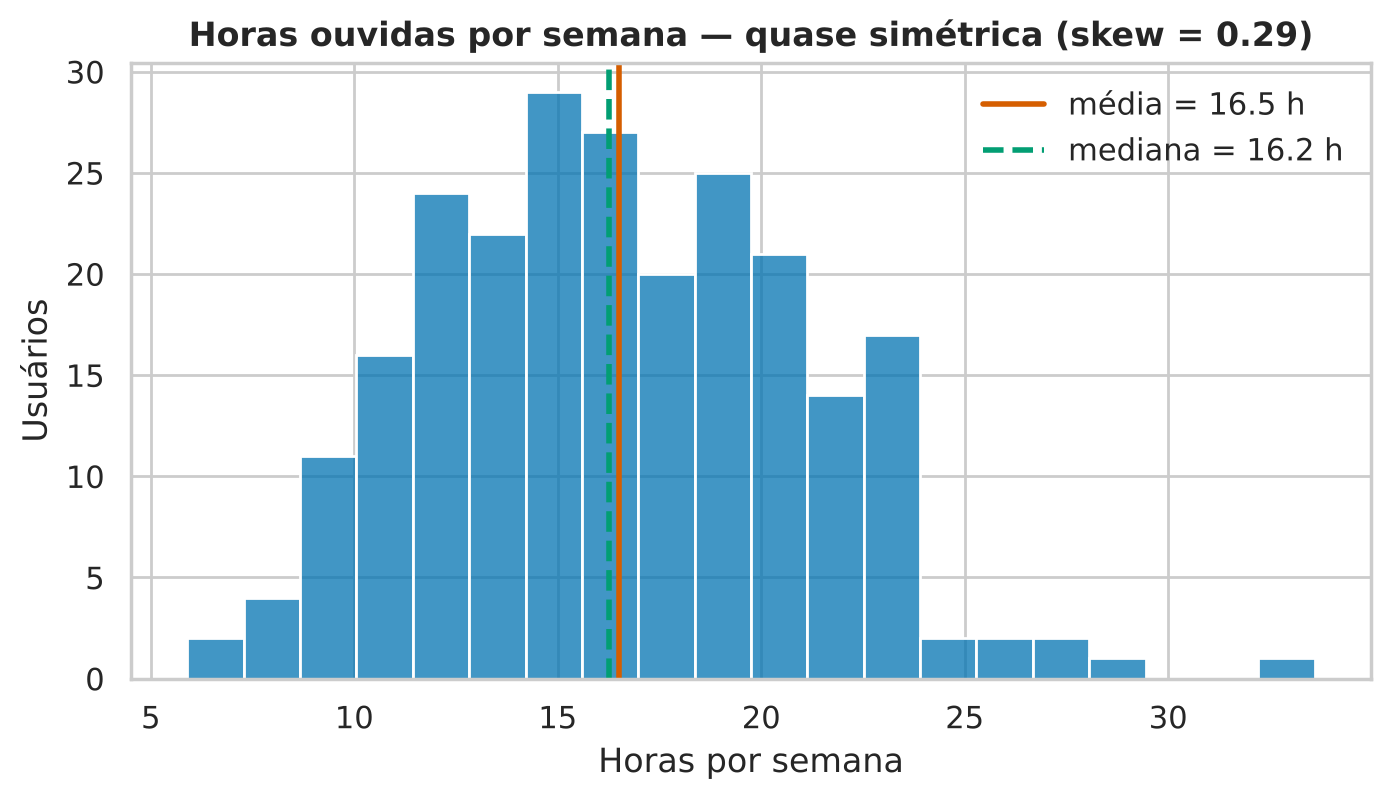

In [3]:
h = m["horas_semana"]
media, mediana = h.mean(), h.median()
print(f"média={media:.2f} | mediana={mediana:.2f} | dp={h.std():.2f} | skew={h.skew():.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(h, bins=20, color="#0173b2", edgecolor="white", ax=ax)
ax.axvline(media, color="#d55e00", lw=2, label=f"média = {media:.1f} h")
ax.axvline(mediana, color="#029e73", lw=2, ls="--", label=f"mediana = {mediana:.1f} h")
ax.set(title=f"Horas ouvidas por semana — quase simétrica (skew = {h.skew():.2f})",
       xlabel="Horas por semana", ylabel="Usuários")
ax.legend(frameon=False)
plt.show()

## Passo 3 — Boxplot de `horas_semana` por plano, com *n* e medianas

Calcule Q1, mediana, Q3 e IQR de cada plano. Faça o boxplot com `showmeans=True`, escreva a mediana ao lado de cada caixa e o *n* no rótulo do eixo x.

> ✅ **Resultado esperado:** Gratuito: mediana **15,3 h** (Q1 = 12,0; Q3 = 18,65; IQR ≈ 6,7). Premium: mediana **18,5 h** (Q1 = 14,7; Q3 = 21,7; IQR = 7,0). Usuários Premium ouvem ~3 h a mais. No conjunto todo há **1 outlier** pelo critério de Tukey (acima de ≈ 29,8 h).

          0.25  0.50   0.75
plano                      
Gratuito  12.0  15.3  18.65
Premium   14.7  18.5  21.70


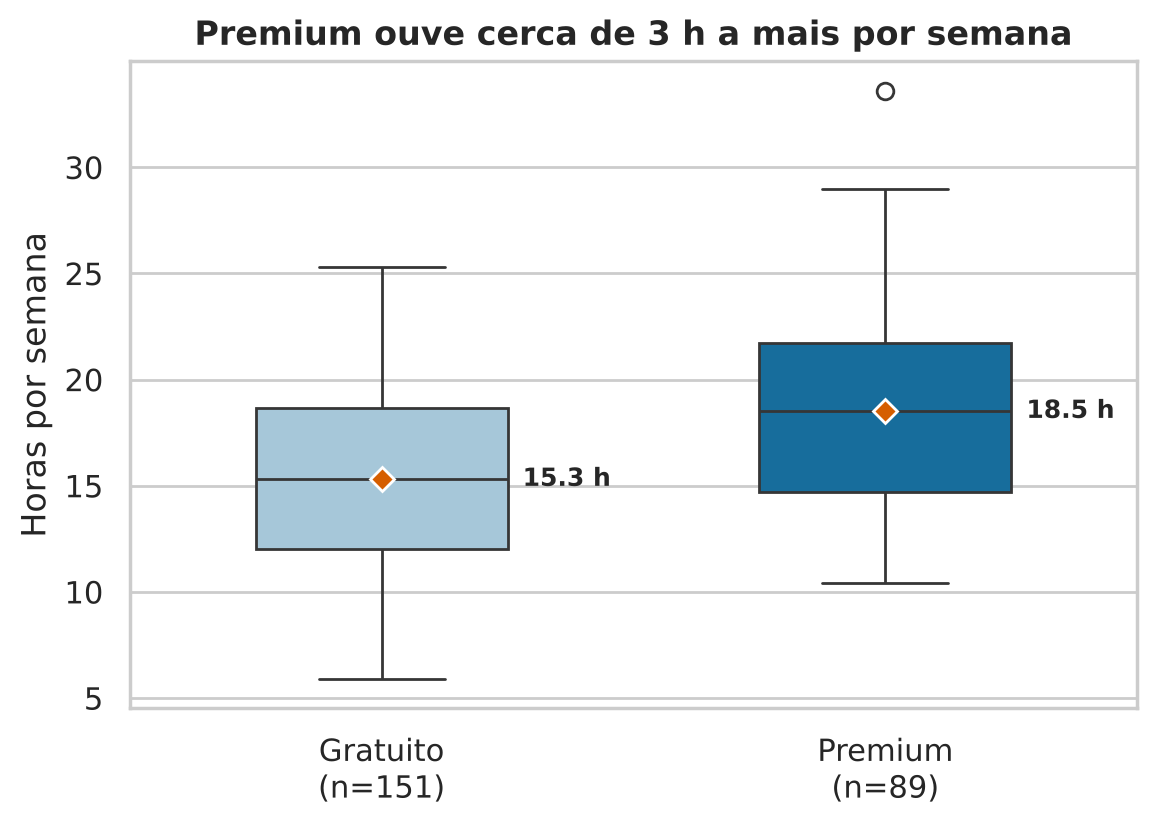

In [4]:
print(m.groupby("plano")["horas_semana"].quantile([.25, .5, .75]).unstack())
n = m["plano"].value_counts(); med = m.groupby("plano")["horas_semana"].median()
ordem = ["Gratuito", "Premium"]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.boxplot(data=m, x="plano", y="horas_semana", order=ordem, hue="plano", palette=CORES_PLANO,
            legend=False, width=0.5, showmeans=True,
            meanprops=dict(marker="D", markerfacecolor="#d55e00", markeredgecolor="white"), ax=ax)
for i, p in enumerate(ordem):
    ax.text(i + 0.28, med[p], f"{med[p]:.1f} h", va="center", fontweight="bold", fontsize=9)
ax.set_xticks([0, 1], [f"{p}\n(n={n[p]})" for p in ordem])
ax.set(title="Premium ouve cerca de 3 h a mais por semana", xlabel="", ylabel="Horas por semana")
plt.show()

## Passo 4 — Violino da `satisfacao` por plano

Use `sns.violinplot(..., inner="quart", cut=0)` e escreva a mediana de cada grupo no gráfico.

> ✅ **Resultado esperado:** Mediana da satisfação: **Gratuito 3,6** e **Premium 7,3**. As duas distribuições quase não se sobrepõem.

plano
Gratuito    3.6
Premium     7.3
Name: satisfacao, dtype: float64


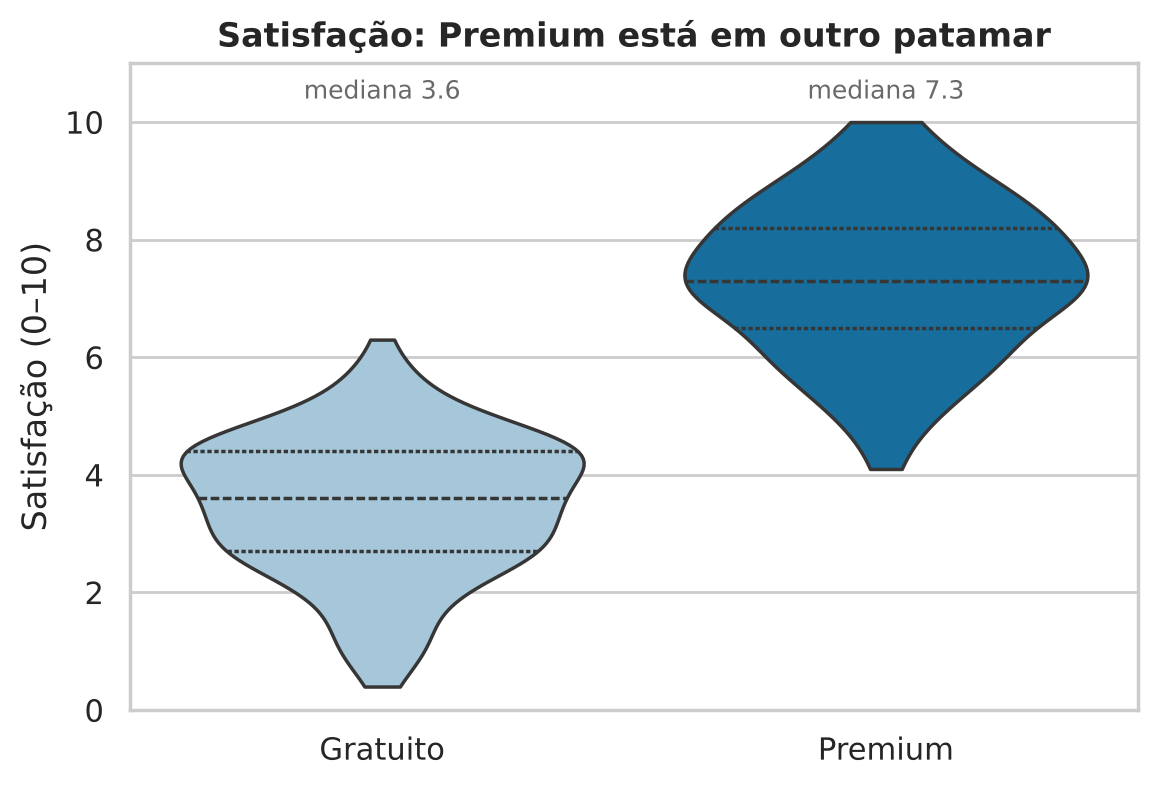

In [5]:
med_s = m.groupby("plano")["satisfacao"].median()
print(med_s)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.violinplot(data=m, x="plano", y="satisfacao", order=["Gratuito", "Premium"], hue="plano",
               palette=CORES_PLANO, legend=False, inner="quart", cut=0, ax=ax)
for i, p in enumerate(["Gratuito", "Premium"]):
    ax.text(i, 10.4, f"mediana {med_s[p]:.1f}", ha="center", fontsize=9, color="dimgray")
ax.set(ylim=(0, 11), title="Satisfação: Premium está em outro patamar", xlabel="", ylabel="Satisfação (0–10)")
plt.show()

## Passo 5 — Dispersão `idade` × `horas_semana` com r e reta de regressão

Calcule Pearson, Spearman e a reta (`stats.linregress`). Desenhe com `scatterplot` (cor = plano) + `regplot(scatter=False)` e escreva r e a equação numa caixa de texto.

> ✅ **Resultado esperado:** Pearson **r ≈ −0,65**, Spearman ρ ≈ −0,66; reta **horas ≈ 25,0 − 0,21 × idade** → a cada 10 anos a mais, cerca de 2,1 h a menos por semana.

r=-0.65 | rho=-0.66 | horas = 25.0 + -0.21 x idade


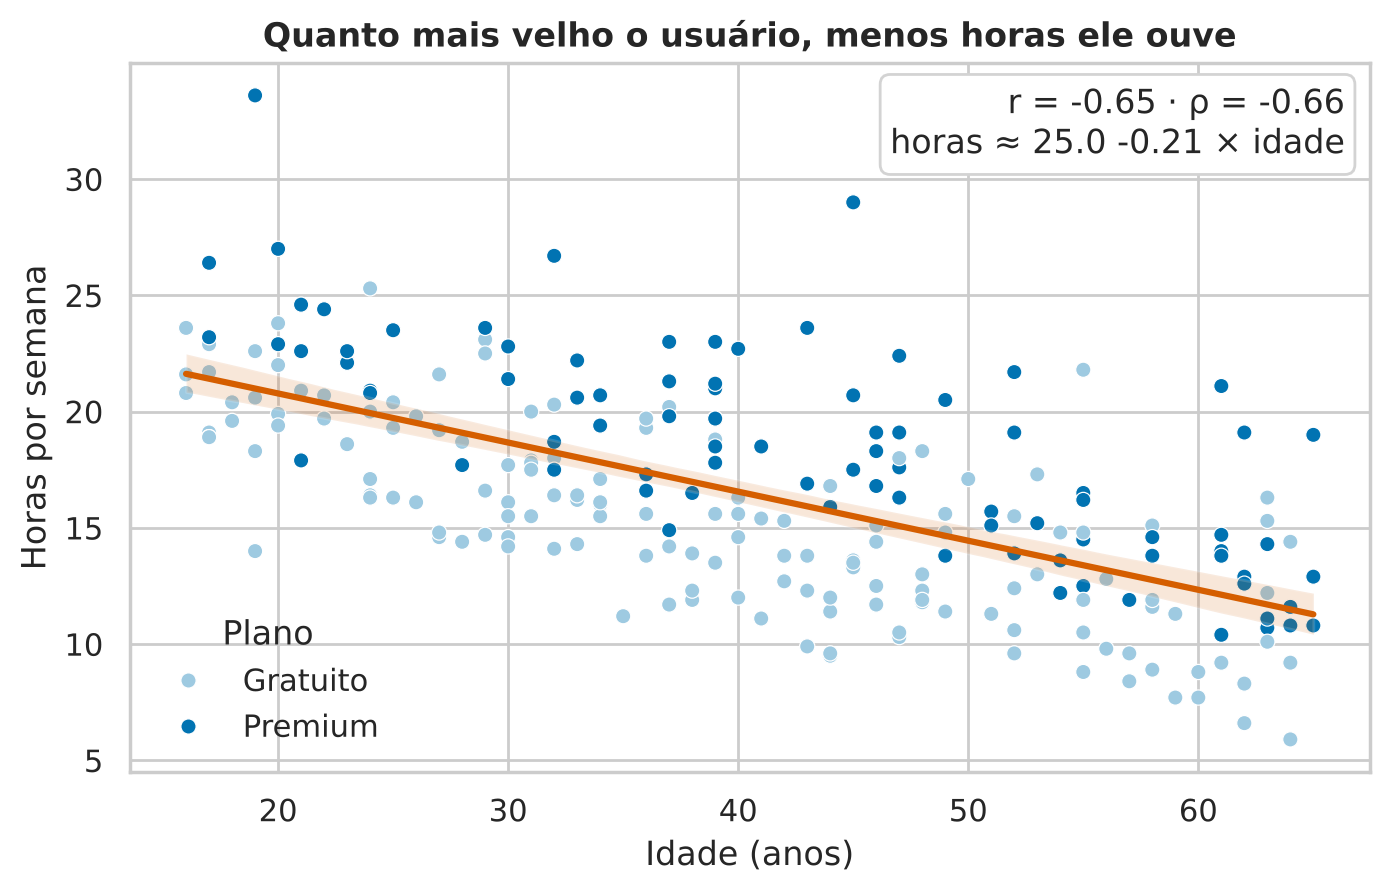

In [6]:
x, y = m["idade"], m["horas_semana"]
r = stats.pearsonr(x, y)[0]; rho = stats.spearmanr(x, y)[0]; reg = stats.linregress(x, y)
print(f"r={r:.2f} | rho={rho:.2f} | horas = {reg.intercept:.1f} + {reg.slope:.2f} x idade")

fig, ax = plt.subplots(figsize=(8, 4.6))
sns.scatterplot(data=m, x="idade", y="horas_semana", hue="plano", palette=CORES_PLANO, s=30, ax=ax)
sns.regplot(data=m, x="idade", y="horas_semana", scatter=False, color="#d55e00", ax=ax)
ax.text(0.98, 0.97, f"r = {r:.2f} · ρ = {rho:.2f}\nhoras ≈ {reg.intercept:.1f} {reg.slope:+.2f} × idade",
        transform=ax.transAxes, ha="right", va="top", bbox=dict(fc="white", ec="lightgray", boxstyle="round"))
ax.set(title="Quanto mais velho o usuário, menos horas ele ouve", xlabel="Idade (anos)", ylabel="Horas por semana")
ax.legend(title="Plano", frameon=False, loc="lower left")
plt.show()

## Passo 6 — Barras: horas médias por gênero favorito (IC 95% e *n*)

Ordene os gêneros pela média, use `sns.barplot(..., errorbar=("ci", 95))` e escreva o *n* de cada barra. Destaque o maior valor com outra cor.

> ✅ **Resultado esperado:** **Eletrônica 19,6 h** (n = 30) é o maior; **Rock 15,0 h** (n = 34) o menor; MPB, Forró, Pop e Sertanejo ficam entre 15,9 e 16,7 h, com intervalos de confiança que se sobrepõem bastante.

                 media   n
genero_favorito           
Eletrônica        19.6  30
Sertanejo         16.7  47
Pop               16.2  63
Forró             16.1  31
MPB               15.9  35
Rock              15.0  34


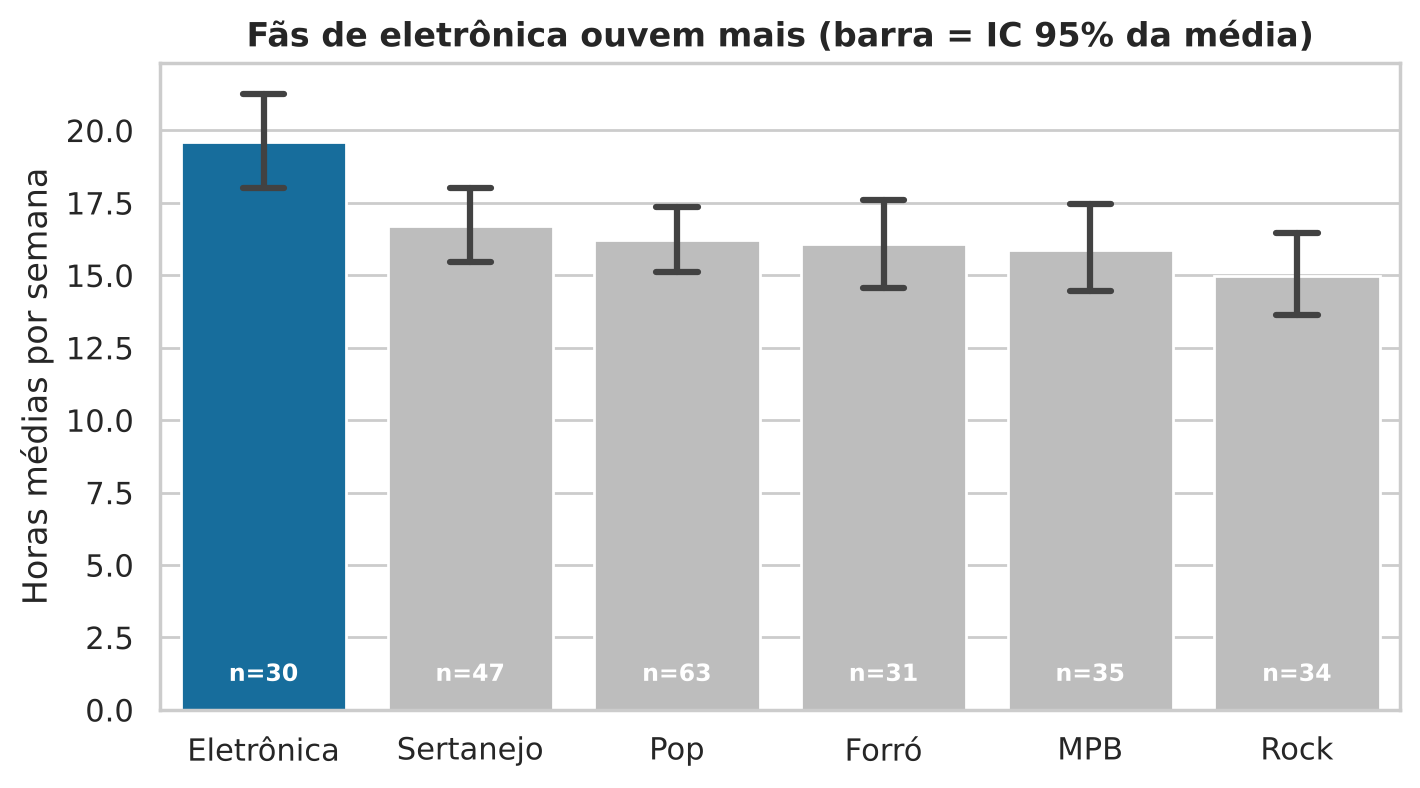

In [7]:
resumo = m.groupby("genero_favorito")["horas_semana"].agg(media="mean", n="size").sort_values("media", ascending=False)
print(resumo.round(1))
ordem = resumo.index
cores = ["#0173b2" if g == ordem[0] else "#bdbdbd" for g in ordem]

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=m, x="genero_favorito", y="horas_semana", order=ordem, hue="genero_favorito",
            palette=dict(zip(ordem, cores)), legend=False, errorbar=("ci", 95), capsize=0.2, seed=1, ax=ax)
for i, g in enumerate(ordem):
    ax.text(i, 1, f"n={resumo.loc[g, 'n']}", ha="center", color="white", fontweight="bold", fontsize=8.5)
ax.set(title="Fãs de eletrônica ouvem mais (barra = IC 95% da média)", xlabel="", ylabel="Horas médias por semana")
plt.show()

## Passo 7 — Mapa de calor da correlação

Monte a matriz com as colunas numéricas (sem `usuario_id`), use paleta divergente `vlag` com `center=0`, `vmin=-1`, `vmax=1`, `annot=True` e máscara do triângulo superior. **Desafio:** recalcule anúncios × satisfação **só para o plano Gratuito**.

> ✅ **Resultado esperado:** Par mais forte: **anúncios × satisfação r = −0,82**; depois idade × horas (−0,65) e playlists × horas (0,54). Só no plano Gratuito, anúncios × satisfação cai para **r ≈ −0,42** — parte da correlação geral vem do **plano** (Premium tem 0 anúncios *e* satisfação alta): variável de confusão.

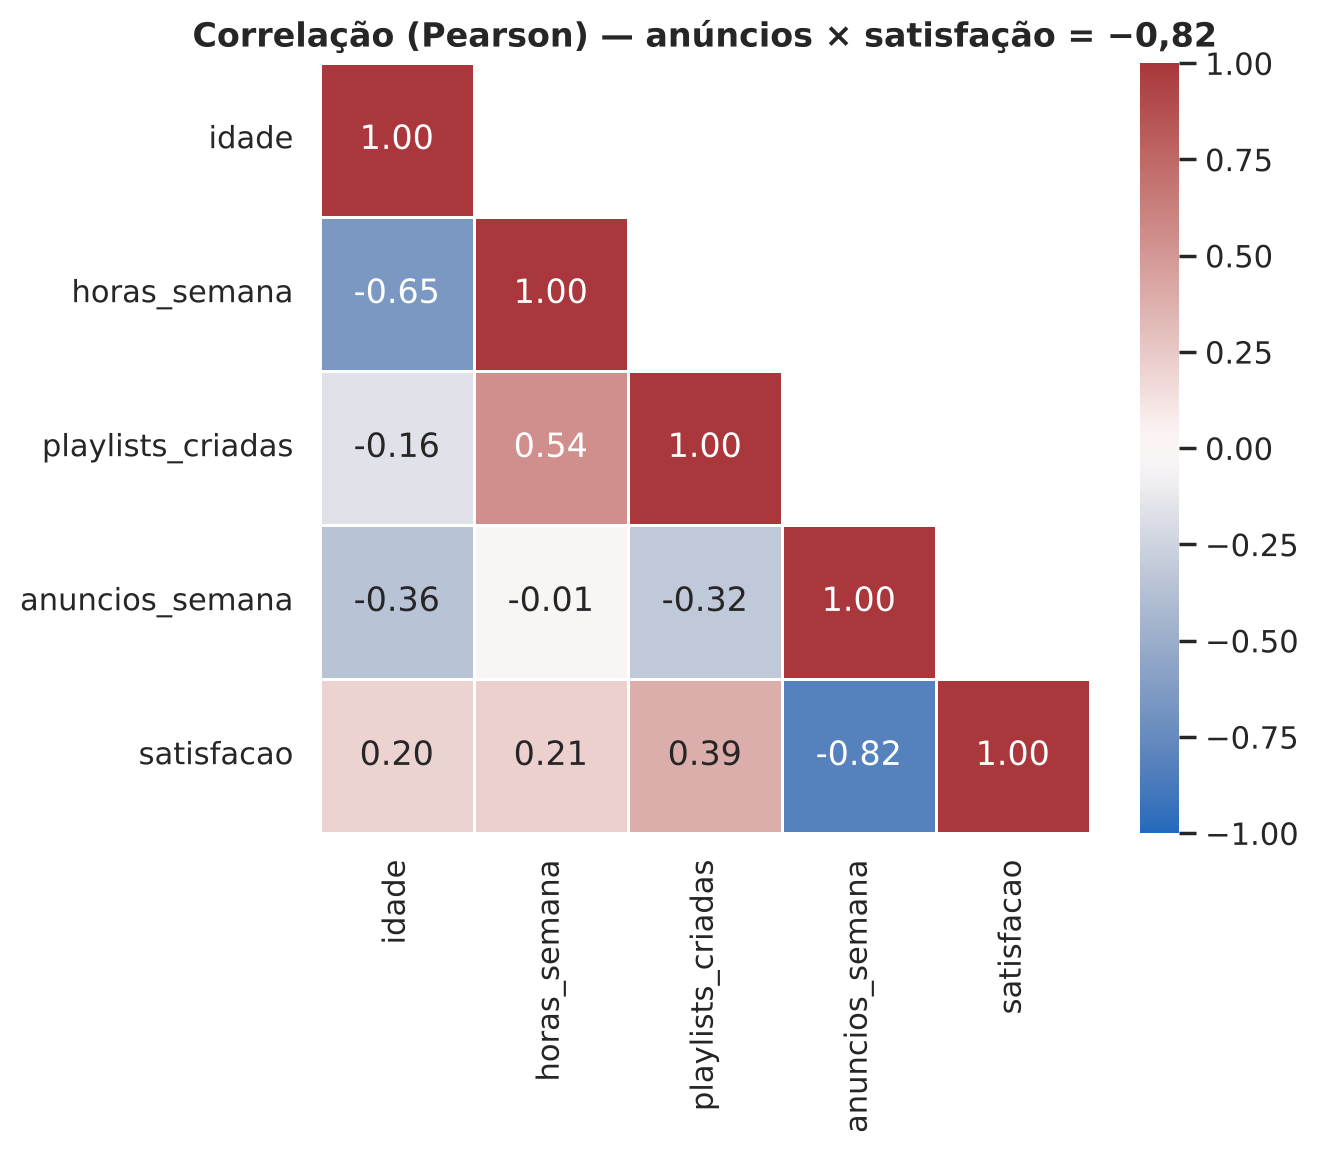

Só Gratuito: r(anúncios, satisfação) = -0.42


In [8]:
cols = ["idade", "horas_semana", "playlists_criadas", "anuncios_semana", "satisfacao"]
corr = m[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            linewidths=1, square=True, ax=ax)
ax.grid(False); ax.set_title("Correlação (Pearson) — anúncios × satisfação = −0,82")
plt.show()

g = m[m["plano"] == "Gratuito"]
print("Só Gratuito: r(anúncios, satisfação) =", round(stats.pearsonr(g["anuncios_semana"], g["satisfacao"])[0], 2))

## Passo 8 — Customização: painel 2×2 para a diretoria

Monte `fig, axes = plt.subplots(2, 2, figsize=(12, 8))` com os gráficos dos passos 2, 3, 5 e 7. Use `fig.suptitle` com a principal conclusão, rodapé com a fonte e salve em `figuras/exercicio_painel.png` com `dpi=200, bbox_inches="tight"`.

> ✅ **Resultado esperado:** Arquivo `figuras/exercicio_painel.png` criado; títulos com conclusões, eixos com unidades, mesma cor para o mesmo plano nos quatro painéis.

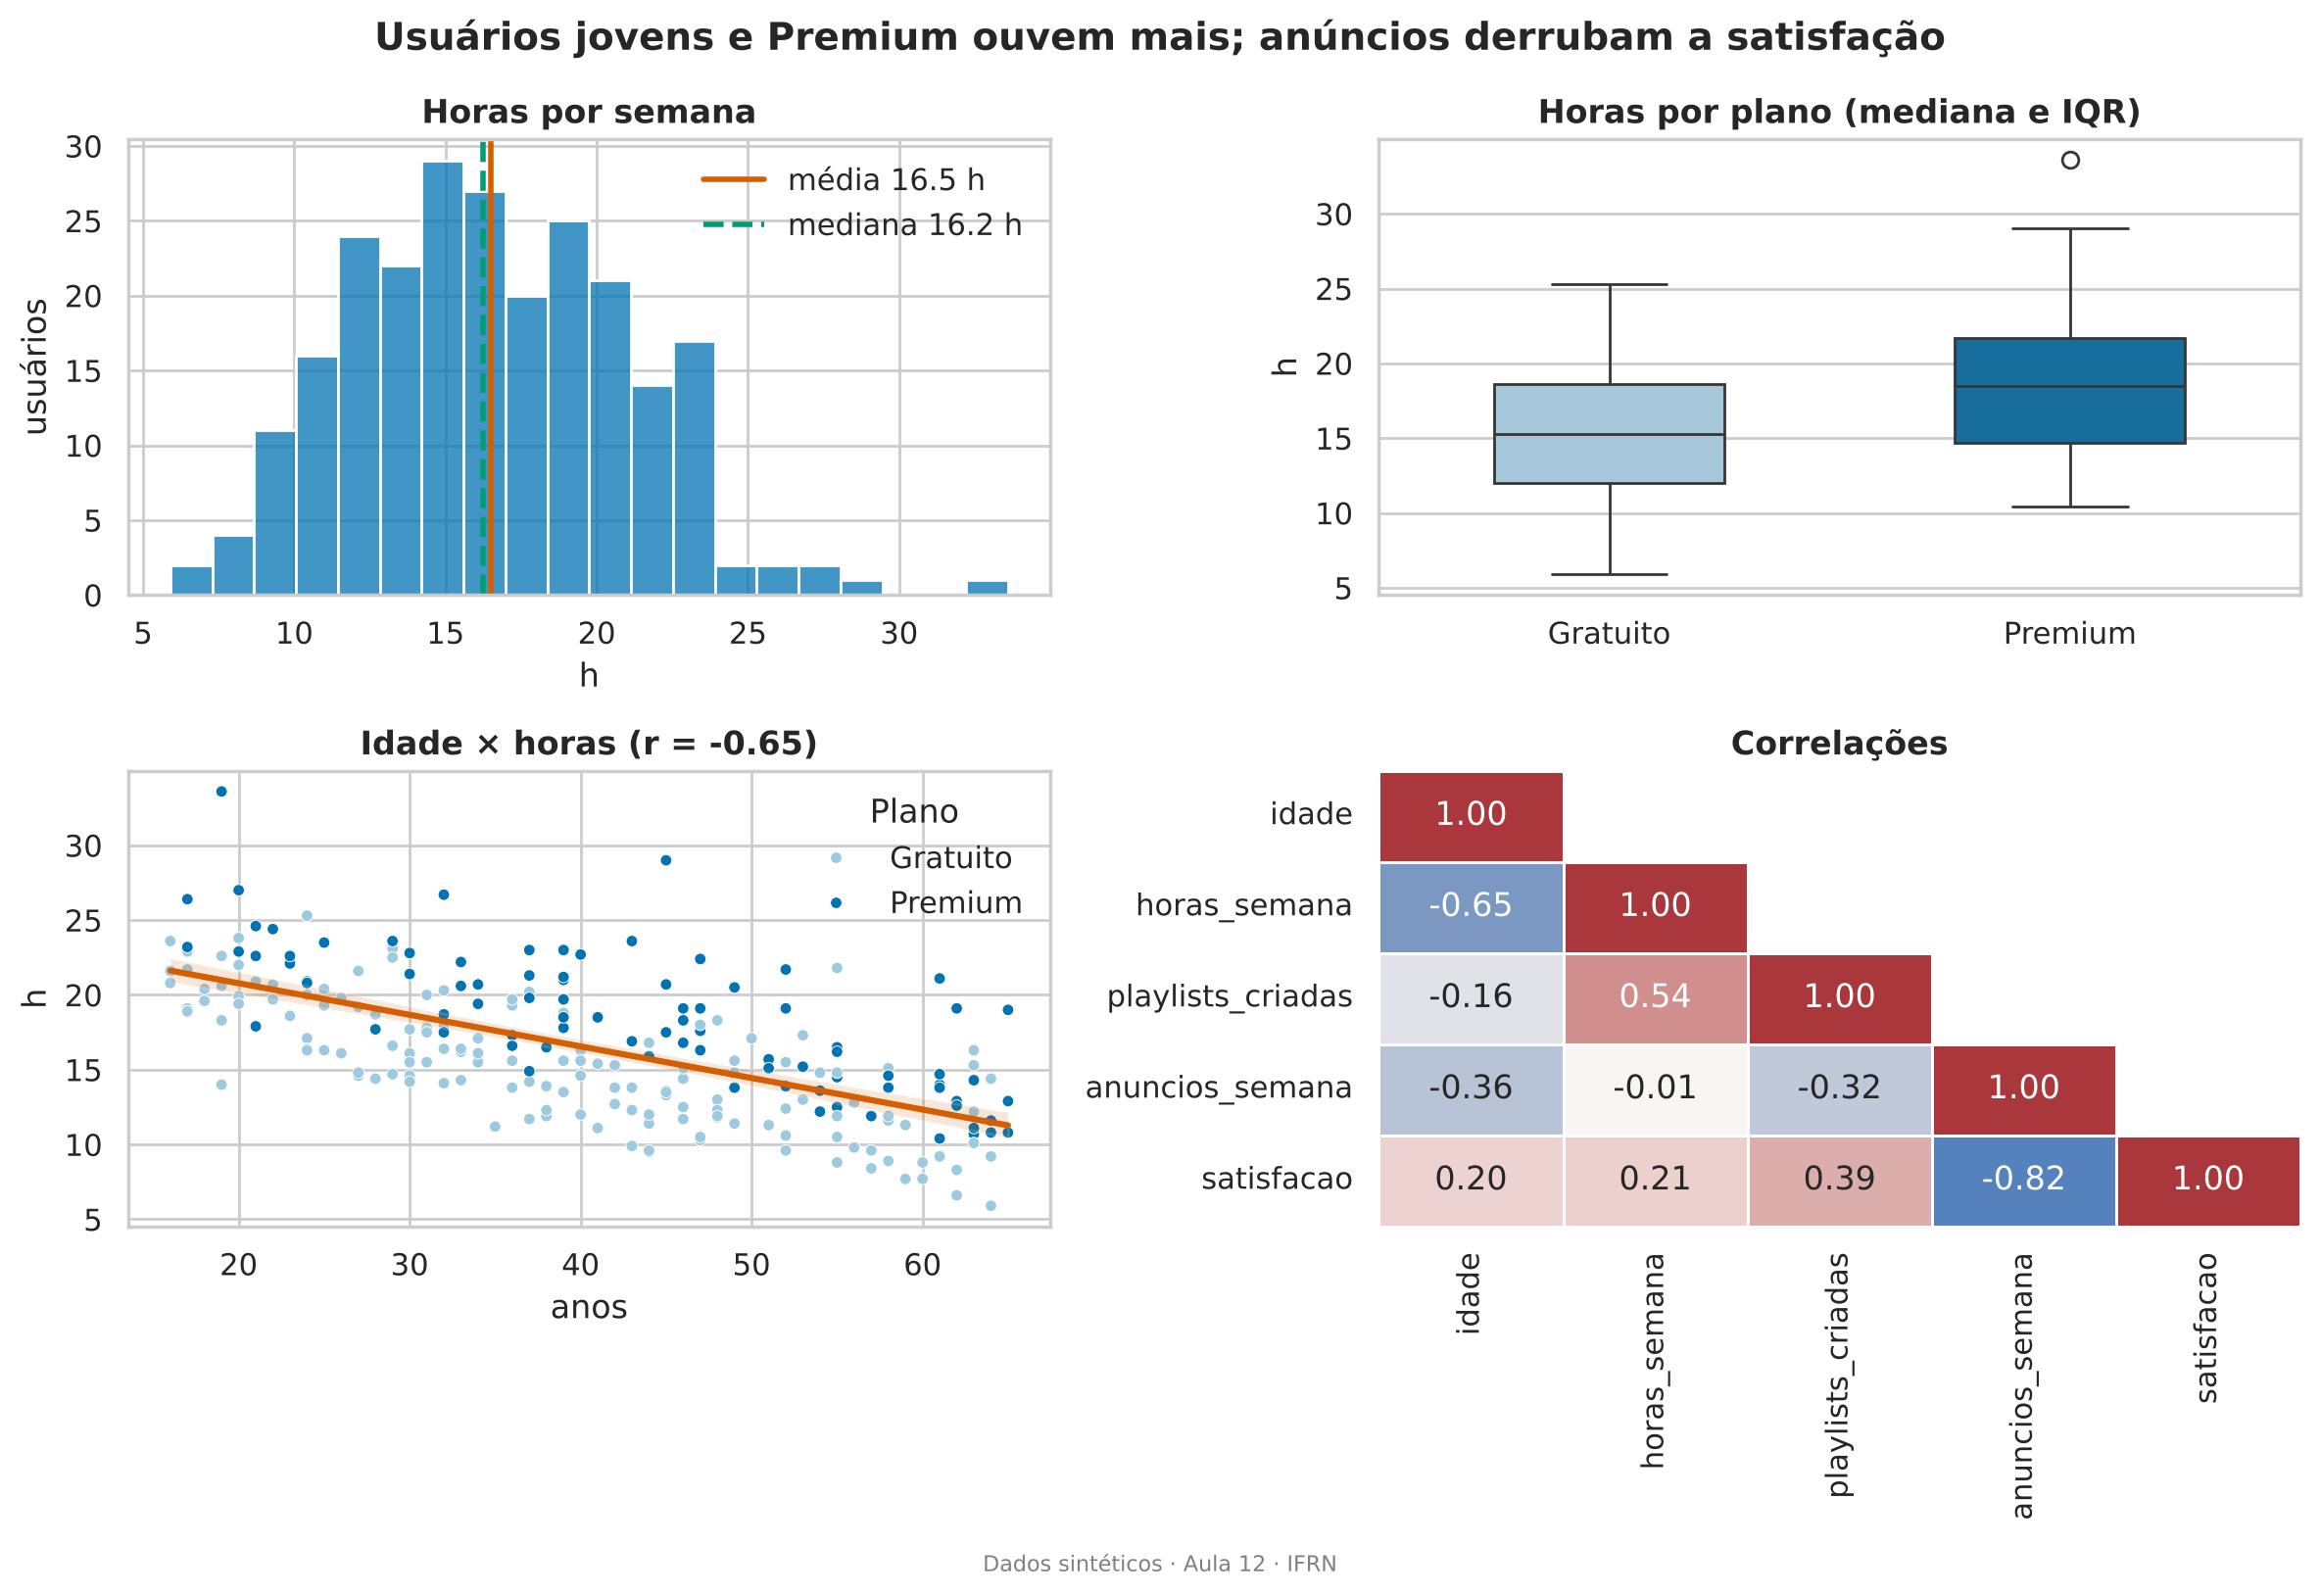

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
(a, b), (c, d) = axes
sns.histplot(h, bins=20, color="#0173b2", edgecolor="white", ax=a)
a.axvline(media, color="#d55e00", lw=2, label=f"média {media:.1f} h")
a.axvline(mediana, color="#029e73", ls="--", lw=2, label=f"mediana {mediana:.1f} h")
a.legend(frameon=False); a.set(title="Horas por semana", xlabel="h", ylabel="usuários")
sns.boxplot(data=m, x="plano", y="horas_semana", order=["Gratuito", "Premium"], hue="plano",
            palette=CORES_PLANO, legend=False, width=0.5, ax=b)
b.set(title="Horas por plano (mediana e IQR)", xlabel="", ylabel="h")
sns.scatterplot(data=m, x="idade", y="horas_semana", hue="plano", palette=CORES_PLANO, s=18, ax=c)
sns.regplot(data=m, x="idade", y="horas_semana", scatter=False, color="#d55e00", ax=c)
c.set(title=f"Idade × horas (r = {r:.2f})", xlabel="anos", ylabel="h"); c.legend(frameon=False, title="Plano")
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, cbar=False,
            linewidths=1, ax=d)
d.grid(False); d.set_title("Correlações")
fig.suptitle("Usuários jovens e Premium ouvem mais; anúncios derrubam a satisfação", fontsize=14, fontweight="bold")
fig.text(0.5, -0.01, "Dados sintéticos · Aula 12 · IFRN", ha="center", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig("figuras/exercicio_painel.png", dpi=200, bbox_inches="tight")
plt.show()

## Passo 9 — Plotly: dispersão interativa e exportação para HTML

Com `px.scatter`, faça idade × horas com `color="plano"` e `hover_data=["genero_favorito", "dispositivo", "satisfacao"]`. Salve em `graficos/exercicio_dispersao.html` (`include_plotlyjs="cdn"`). Faça também um `px.box` da satisfação por plano com `points="all"`.

> ✅ **Resultado esperado:** Ao passar o mouse sobre um ponto aparecem idade, horas, gênero, dispositivo e satisfação; o arquivo HTML abre em qualquer navegador. No boxplot, o *hover* mostra mediana 3,6 (Gratuito) e 7,3 (Premium).

In [10]:
fig = px.scatter(m, x="idade", y="horas_semana", color="plano", color_discrete_map=CORES_PLANO,
                 hover_data=["genero_favorito", "dispositivo", "satisfacao"],
                 labels={"idade": "Idade (anos)", "horas_semana": "Horas por semana", "plano": "Plano"},
                 title=f"Idade × horas por semana (r = {r:.2f})")
fig.update_layout(template="plotly_white")
fig.write_html("graficos/exercicio_dispersao.html", include_plotlyjs="cdn")
fig.show()

fig = px.box(m, x="plano", y="satisfacao", color="plano", points="all", color_discrete_map=CORES_PLANO,
             labels={"satisfacao": "Satisfação (0–10)", "plano": "Plano"}, title="Satisfação por plano")
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

## Para refletir
1. Em qual passo a **mediana** comunicou melhor que a média? Por quê?
2. O r = −0,82 entre anúncios e satisfação significa que *cada* anúncio reduz a satisfação? O que o desafio do passo 7 mostrou?
3. Qual dos gráficos você colocaria **sozinho** num slide para a diretoria? Que título daria a ele?